# 🕺 원하는 포즈로 이미지 만드는 도구

사람 사진 한 장을 넣으면 **그 사람과 똑같은 자세**를 한 *다른 인물/장면*을 만들어 주는 도구입니다.

## 어떻게 동작하나요? (한 줄 비유)
1. **OpenPose** 가 사진 속 사람의 관절(머리·어깨·팔꿈치·손목·무릎…)을 찾아 **막대 인형 그림(뼈대)** 으로 바꿉니다.
2. **ControlNet** 이 그 막대 인형을 보고 "이 자세 그대로 그려!" 라고 그림 모델에게 귓속말합니다.
3. **그림 모델(Stable Diffusion 1.5)** 이 프롬프트(글)대로 인물·배경을 그리되, 자세는 막대 인형을 따라갑니다.

```
사람 사진 ──OpenPose──▶ 막대 인형(뼈대) ──ControlNet──▶ 그림 모델 + 프롬프트 ──▶ 같은 자세의 새 그림
```

## 왜 FLUX.2-klein 이 아니라 SD 1.5 인가요?
교안 출발점은 FLUX.2-klein 4B 지만, 교안에도 적혀 있듯 **FLUX.2 에는 공식 ControlNet(포즈)이 없습니다.**
그래서 무료 Colab T4(약 15GB)에서 확실히 돌아가는 **"비슷한 모델"** 인 Stable Diffusion 1.5 + 공식 OpenPose ControlNet 을 씁니다.
(둘 다 이미지 확산 모델이고, 흐름은 FLUX 에서도 똑같습니다.)

## 순서
| 셀 | 하는 일 |
|---|---|
| 0 | GPU 붙었는지 확인 |
| 1 | 필요한 프로그램 설치 |
| 2 | 모델 불러오기 |
| 3 | 참조 사진 준비 |
| 4 | 포즈(뼈대) 추출 |
| 5 | 이미지 생성 |
| 6 | 결과 저장 |
| 7~8 | 실험: 프롬프트 바꾸기 / 포즈 바꾸기 |
| 9 | 결과 내려받기 |
| 마지막 | 관찰 기록 |

> ⚠️ 시작 전에: 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 꼭 고르세요.

## 셀 0. GPU 확인
그래픽카드(GPU)가 붙어 있어야 그림을 빨리 만들 수 있습니다. 안 붙어 있으면 여기서 멈춥니다.

In [1]:
# [이 셀이 하는 일] GPU가 붙었는지, 어떤 GPU인지, 메모리(VRAM)가 얼마인지 확인한다.
import torch
if not torch.cuda.is_available():
    raise SystemExit("GPU가 안 붙었습니다. 메뉴 '런타임 → 런타임 유형 변경'에서 T4 GPU를 고르고 다시 실행하세요.")
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} / VRAM {p.total_memory / 1024**3:.1f}GB")

GPU: Tesla T4 / VRAM 14.6GB


## 셀 1. 프로그램 설치
- `diffusers` : 그림 모델을 쉽게 쓰게 해 주는 도구
- `controlnet_aux` : 사진에서 관절(포즈)을 뽑아 주는 도구(OpenPose 포함)

1~2분 걸립니다. 빨간 경고 글씨가 나와도 마지막에 `설치 완료` 가 찍히면 괜찮습니다.

In [2]:
# [이 셀이 하는 일] 그림 모델 도구(diffusers)와 포즈 추출 도구(controlnet_aux)를 설치한다.
!pip install -q -U diffusers transformers accelerate controlnet_aux
print("설치 완료")

설치 완료


## 셀 2. 모델 불러오기
세 가지를 인터넷(Hugging Face)에서 내려받아 GPU에 올립니다. 처음엔 2~5분 걸립니다.
1. **포즈 추출기** (OpenPose)
2. **ControlNet** (포즈 전용)
3. **그림 모델** (Stable Diffusion 1.5)

In [5]:
# [이 셀이 하는 일] 포즈 추출기, 포즈용 ControlNet, 그림 모델을 내려받아 GPU에 올린다.
import torch
from controlnet_aux import OpenposeDetector
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler

# 1) 사진 → 막대 인형(뼈대)으로 바꿔 주는 OpenPose
openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")

# 2) 막대 인형을 읽어서 그림 모델에게 자세를 알려 주는 ControlNet (OpenPose 전용)
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_openpose", torch_dtype=torch.float16
)

# 3) 실제로 그림을 그리는 모델 + ControlNet을 하나로 묶은 '파이프라인'
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,   # 반 정밀도: 메모리를 절반만 쓴다
    safety_checker=None,
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)  # 적은 스텝으로도 잘 그리는 방식
pipe = pipe.to("cuda")
print("모델 준비 완료")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


모델 준비 완료


## 셀 3. 참조 사진 준비
"이 자세로 그려 줘" 할 때의 **그 자세 사진**을 2장 준비합니다.

- `pose_01` : 비워 두면 예시 사진(인터넷)을 씁니다.
- `pose_02` : **내 사진을 올리는 것을 추천**합니다. (예: 의자에 앉은 자세, 두 팔 벌린 자세)

**좋은 참조 사진 고르는 법**
- 사람이 **한 명**만, **머리부터 발끝까지** 다 보이게
- 팔다리가 몸에 가려지지 않게 (팔을 벌리거나 든 자세가 잘 됨)
- 너무 어둡지 않게

`USE_UPLOAD = True` 로 두고 실행하면 **파일 선택 버튼**이 나옵니다. 사진 2장을 한꺼번에 고르세요(첫 번째 → pose_01, 두 번째 → pose_02).

Saving Gemini_Generated_Image_5rwi645rwi645rwi.png to Gemini_Generated_Image_5rwi645rwi645rwi (1).png
Saving Gemini_Generated_Image_fiqc0ffiqc0ffiqc.png to Gemini_Generated_Image_fiqc0ffiqc0ffiqc (1).png


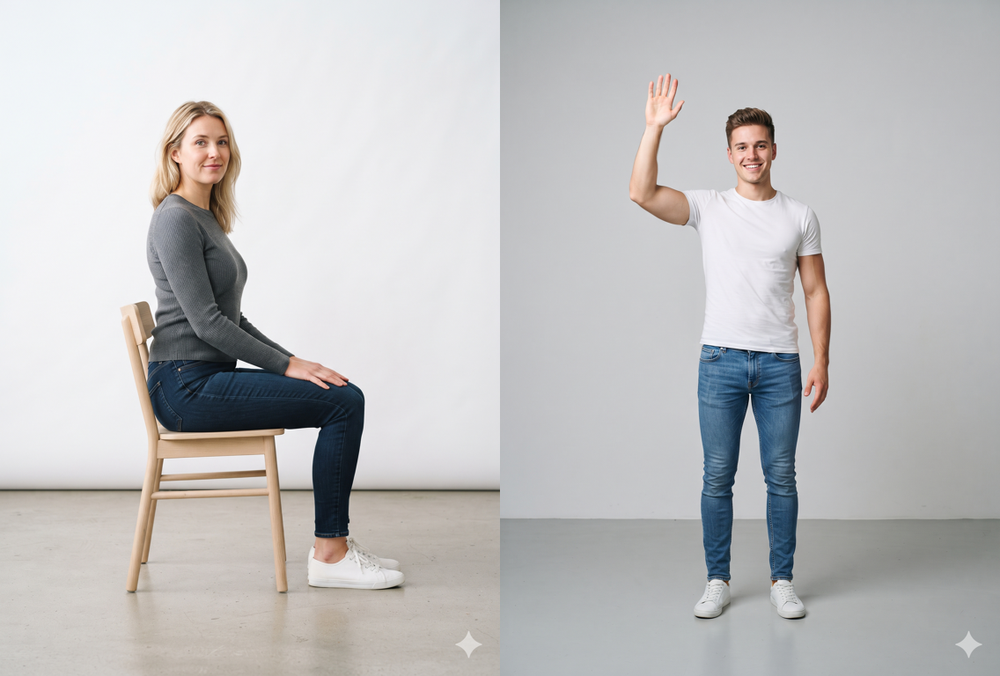

In [9]:
# [이 셀이 하는 일] 자세를 따라 할 참조 사진 2장을 불러오고, samples/ 폴더에 pose_01.png, pose_02.png로 저장한다.
import os
from PIL import Image
from diffusers.utils import load_image, make_image_grid

os.makedirs("samples", exist_ok=True)

USE_UPLOAD = True   # True: 내 컴퓨터에서 사진 올리기 / False: 아래 예시 주소 사용
EXAMPLE_URL = "https://huggingface.co/lllyasviel/control_v11p_sd15_openpose/resolve/main/images/input.png"

def fit(img, long_side=768):
    # 사진 크기를 모델이 좋아하는 크기(긴 쪽 768, 8의 배수)로 맞춘다
    img = img.convert("RGB")
    w, h = img.size
    s = long_side / max(w, h)
    return img.resize((int(w * s) // 8 * 8, int(h * s) // 8 * 8))

refs = []
if USE_UPLOAD:
    from google.colab import files
    uploaded = files.upload()               # ← 여기서 '파일 선택' 버튼이 뜬다
    for name in list(uploaded)[:2]:
        refs.append(fit(Image.open(name)))
while len(refs) < 2:                         # 사진이 모자라면 예시 사진으로 채운다
    refs.append(fit(load_image(EXAMPLE_URL)))

for i, img in enumerate(refs, start=1):
    img.save(f"samples/pose_{i:02d}.png")
make_image_grid(refs, rows=1, cols=len(refs))

## 셀 4. 포즈(뼈대) 추출
사진에서 관절을 찾아 **검은 바탕 위의 색깔 막대 인형**으로 바꿉니다.
막대 인형이 이상하면(팔이 없거나 엉뚱한 곳에 있으면) 결과도 이상해집니다 → 다른 사진을 쓰세요.

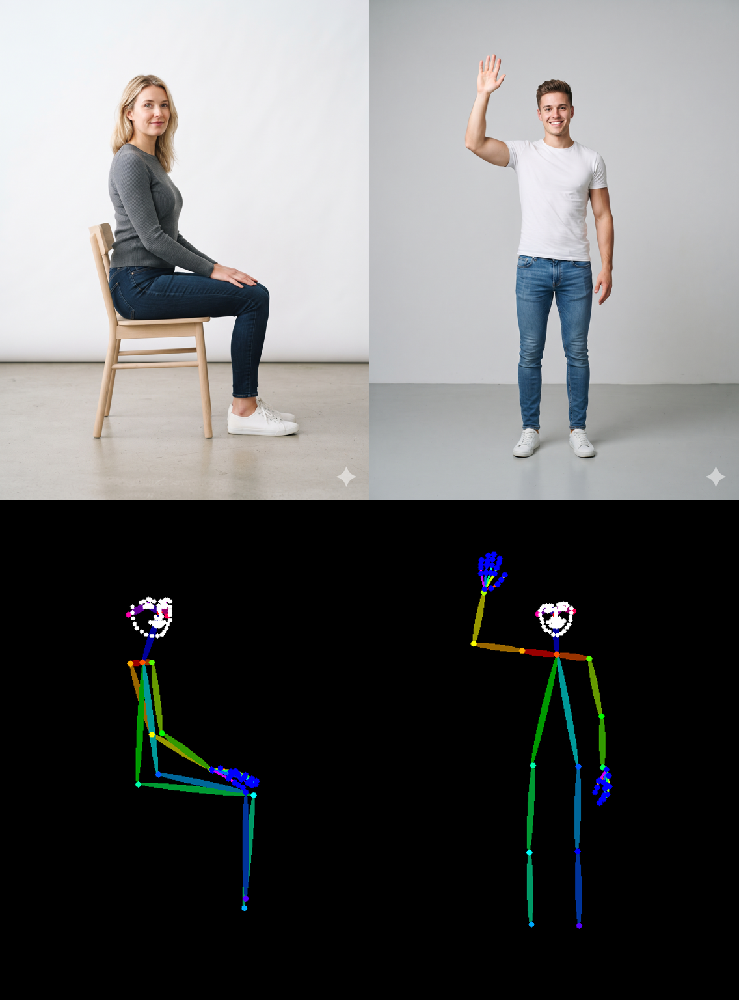

In [10]:
# [이 셀이 하는 일] 참조 사진에서 OpenPose로 관절을 뽑아 '막대 인형' 그림을 만든다.
def extract_pose(img):
    pose = openpose(img, hand_and_face=True)   # 몸 + 손가락 + 얼굴 점까지 찾는다
    return pose.resize(img.size)               # 원래 사진과 같은 크기로 맞춘다

poses = [extract_pose(img) for img in refs]
for i, pose in enumerate(poses, start=1):
    pose.save(f"samples/pose_{i:02d}_skeleton.png")

# 위: 원본 사진 / 아래: 뽑아낸 뼈대
make_image_grid(refs + poses, rows=2, cols=len(refs))

## 셀 5. 이미지 생성
막대 인형 + 프롬프트(영어 문장)를 넣어 그림을 만듭니다. 한 장에 10~20초.

조절할 수 있는 손잡이:
| 이름 | 뜻 | 기본값 |
|---|---|---|
| `prompt` | 무엇을 그릴지 (영어) | |
| `seed` | 같은 숫자면 같은 그림이 나온다 (주사위 번호) | 42 |
| `steps` | 그림을 다듬는 횟수. 많을수록 느리지만 꼼꼼 | 25 |
| `pose_strength` | 자세를 얼마나 꽉 따를지 (0~2) | 1.0 |

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

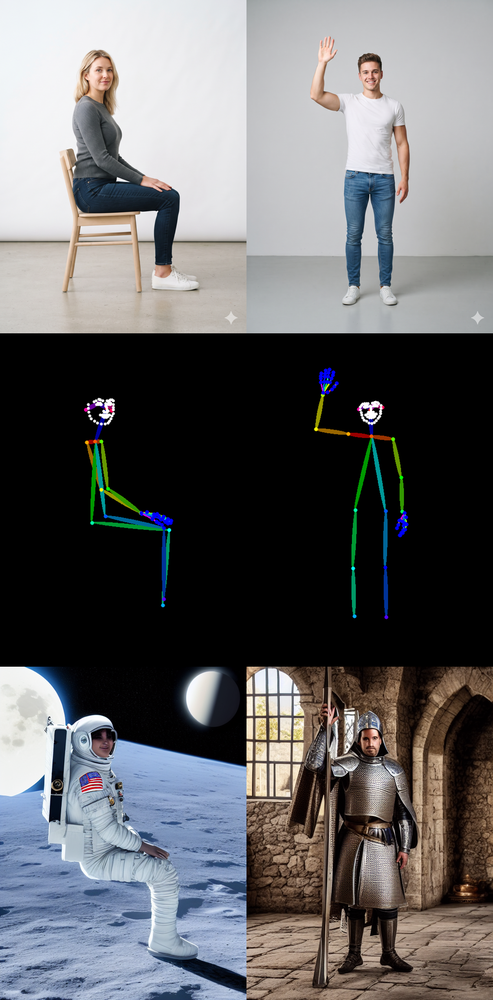

In [11]:
# [이 셀이 하는 일] 뼈대 그림 + 프롬프트를 모델에 넣어 같은 자세의 새 그림을 만든다.
NEGATIVE = "lowres, bad anatomy, extra limbs, extra fingers, missing fingers, deformed, blurry, worst quality"

def generate(pose, prompt, seed=42, steps=25, pose_strength=1.0):
    g = torch.Generator("cuda").manual_seed(seed)   # seed가 같으면 결과도 같다 (재현용)
    return pipe(
        prompt + ", best quality, highly detailed",
        negative_prompt=NEGATIVE,
        image=pose,                                  # ← 여기가 '이 자세로 그려!' 부분
        num_inference_steps=steps,
        controlnet_conditioning_scale=pose_strength,
        generator=g,
        width=pose.width, height=pose.height,
    ).images[0]

PROMPT_1 = "an astronaut in a white space suit on the moon, photo"
PROMPT_2 = "a knight in shining armor in a medieval castle, photo"

outputs = [generate(poses[0], PROMPT_1), generate(poses[1], PROMPT_2)]

# 위: 참조 사진 / 가운데: 뼈대 / 아래: 결과
make_image_grid(refs + poses + outputs, rows=3, cols=2)

## 셀 6. 결과 저장
결과를 `samples/output_01.png`, `output_02.png` 로 저장합니다. (과제 제출 폴더 구조와 같은 이름)

In [12]:
# [이 셀이 하는 일] 만든 그림을 samples/ 폴더에 output_01.png, output_02.png로 저장한다.
for i, out in enumerate(outputs, start=1):
    out.save(f"samples/output_{i:02d}.png")
print(sorted(os.listdir("samples")))

['output_01.png', 'output_02.png', 'pose_01.png', 'pose_01_skeleton.png', 'pose_02.png', 'pose_02_skeleton.png']


## 셀 7. 실험 A — 같은 포즈 + 다른 프롬프트
포즈는 `pose_01` 로 고정하고 **글만 바꿔** 봅니다. seed 도 같게 둬서 '글' 말고는 아무것도 안 바뀌게 합니다.

👀 볼 것: 자세는 그대로인가? 옷·배경·사람은 프롬프트대로 바뀌었나?

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

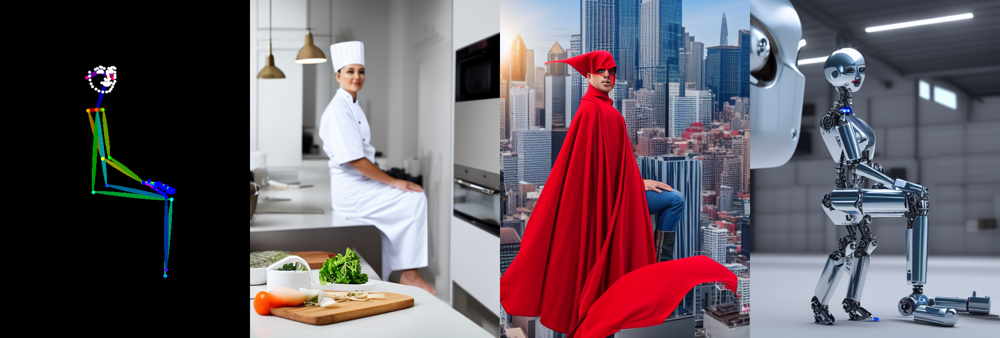

In [13]:
# [이 셀이 하는 일] 포즈는 고정하고 프롬프트만 3가지로 바꿔서, 무엇이 바뀌고 무엇이 그대로인지 비교한다.
EXP_A_PROMPTS = [
    "a chef in a white uniform in a kitchen, photo",
    "a superhero in a red cape on a city rooftop, comic style",
    "a robot made of shiny metal in a factory, 3d render",
]
exp_a = [generate(poses[0], p, seed=42) for p in EXP_A_PROMPTS]
for i, img in enumerate(exp_a, start=1):
    img.save(f"samples/expA_{i}.png")
make_image_grid([poses[0]] + exp_a, rows=1, cols=4)

## 셀 8. 실험 B — 같은 프롬프트 + 다른 포즈
이번엔 **글은 고정**하고 포즈만 바꿉니다. 추가로 `pose_strength` 를 0.5 / 1.0 / 1.5 로 바꿔 봅니다.

👀 볼 것: 프롬프트가 같아도 자세가 바뀌나? 손·발은 잘 따라오나? 세기를 낮추면 어떻게 되나?

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

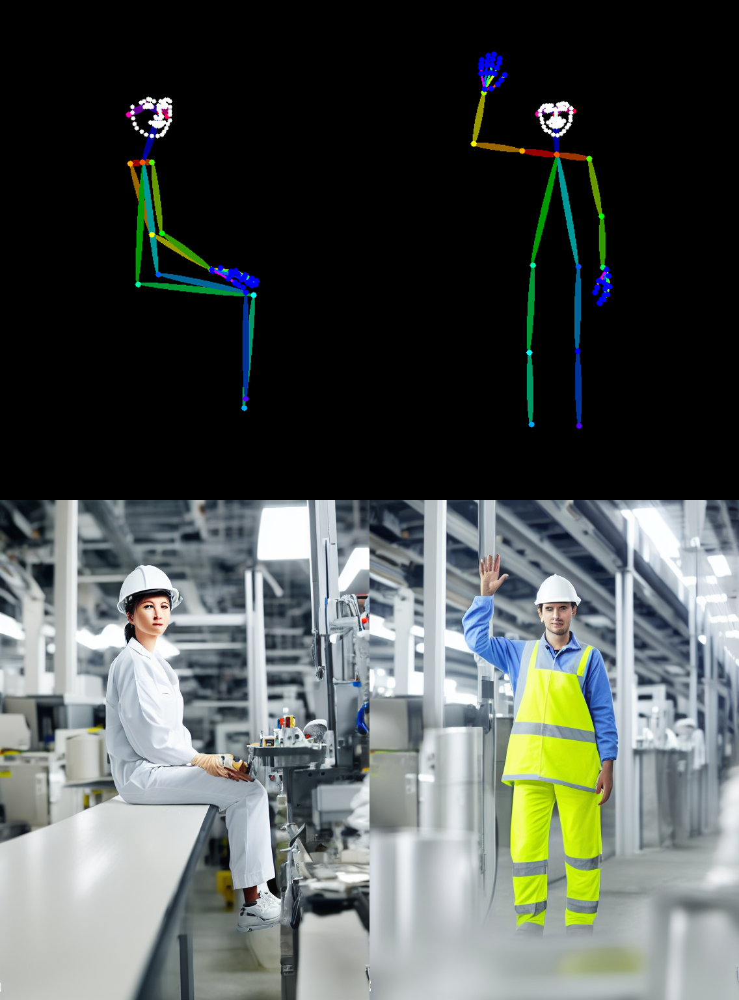

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

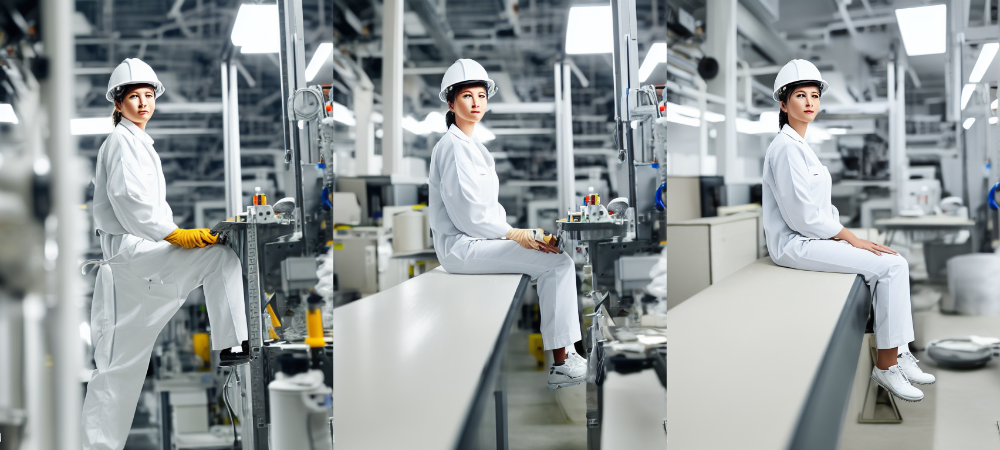

In [15]:
# [이 셀이 하는 일] 프롬프트는 고정하고 포즈를 바꿔 본다. 그리고 포즈 세기(pose_strength)도 바꿔 본다.
SAME_PROMPT = "a factory worker in a white safety helmet and work uniform, photo"

exp_b = [generate(pose, SAME_PROMPT, seed=7) for pose in poses]
for i, img in enumerate(exp_b, start=1):
    img.save(f"samples/expB_pose{i}.png")
display(make_image_grid(poses + exp_b, rows=2, cols=2))

# 덤: 포즈 세기 비교 (0.5 = 느슨하게, 1.5 = 꽉)
strengths = [0.5, 1.0, 1.5]
exp_s = [generate(poses[0], SAME_PROMPT, seed=7, pose_strength=s) for s in strengths]
for s, img in zip(strengths, exp_s):
    img.save(f"samples/expB_strength_{s}.png")
make_image_grid(exp_s, rows=1, cols=3)

## 셀 8-2. 포즈 세기 비교 — 두 번째 포즈 (손 든 자세)
셀 8의 세기 비교(0.5 / 1.0 / 1.5)를 두 번째 포즈로도 해 봅니다. 결과는 `samples/expB_pose2_strength_*.png` 에 저장됩니다.

In [ ]:
# [이 셀이 하는 일] 두 번째 포즈(poses[1])에 대해서도 포즈 세기(0.5, 1.0, 1.5) 비교 실험을 진행합니다.
strengths = [0.5, 1.0, 1.5]
exp_s2 = [generate(poses[1], SAME_PROMPT, seed=7, pose_strength=s) for s in strengths]

for s, img in zip(strengths, exp_s2):
    img.save(f"samples/expB_pose2_strength_{s}.png")

# 결과 시각화 (왼쪽부터 0.5, 1.0, 1.5)
print("두 번째 포즈 기준 세기 비교 (0.5 vs 1.0 vs 1.5)")
make_image_grid(exp_s2, rows=1, cols=3)

  0%|          | 0/25 [00:00<?, ?it/s]

## 셀 9. 결과 내려받기
`samples` 폴더를 zip 으로 묶어 내 컴퓨터로 내려받습니다. GitHub에 올릴 때 이 사진들을 씁니다.

In [17]:
# [이 셀이 하는 일] samples 폴더를 samples.zip으로 묶어 내 컴퓨터로 내려받는다.
import shutil
from google.colab import files
shutil.make_archive("samples", "zip", "samples")
files.download("samples.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📝 관찰 기록 — 무엇을 바꿔 보았고, 어떻게 달라졌는가

### 실험 A. 같은 포즈 + 다른 프롬프트 (셀 7)
- 바꾼 것: 프롬프트 (요리사 → 슈퍼히어로 → 로봇), seed 42 고정
- 자세는: 자세는 다 따라서 만들어진것 같은데 얼굴쪽이 너무 뭉개져있다.
- 바뀐 것: 프롬프트대로 포즈는 유지한채 다 표현된것 같다
- 잘 안 된 것: 로봇의 다리부분이 이상하게 나왔다.

### 실험 B. 같은 프롬프트 + 다른 포즈 (셀 8)
- 바꾼 것: 포즈 사진 (pose_01 → pose_02), 프롬프트 고정
- 결과: 같은 작업자 프롬프트인데도 자세는 포즈 사진대로 바뀌었다 (앉은 자세 → 손 든 자세).
- 잘 안 따라온 부분: 두 장이 같은 사람으로 나오지 않았고, 성별도 참조 사진과 맞지 않았다.

### 덤. 포즈 세기 (pose_strength 0.5 / 1.0 / 1.5)
- 결과:
  * **0.5 (약하게)**: 자세가 다소 느슨하게 맞춰지거나 생략되는 경향이 있다. 특히 손가락 같은 미세한 디테일이 아예 표현되지 않고 뭉개지거나 생략되는 문제가 있었다.
  * **1.0 (기본)**: 뼈대의 자세를 안정적으로 따라오면서 자연스러움도 무난하게 유지되었다.
  * **1.5 (강하게)**: 포즈가 강해질수록 손가락의 뼈대 형태가 점점 더 선명하게 잡히며 디테일이 살아났다. 하지만 무리하게 맞추려다 보니 인체가 다소 부자연스럽고 딱딱해지는 부작용도 함께 관찰되었다.

### 결론: 어느 쪽을 바꿨을 때 크게 달라졌나?
- **프롬프트를 바꿨을 때**: 이미지 안의 '인물의 직업(역할), 의상, 배경 분위기' 전체가 완전히 새롭게 디자인되었다.
- **포즈를 바꿨을 때**: 프롬프트 속 공장 근로자의 컨셉은 유지되나, 동작(포즈) 자체는 뼈대를 대략적으로 추종하며 변경되었다.
- **한계점 발견 (매우 중요)**: 동작의 가이드라인(뼈대)은 따라가지만, **인물의 성별이 멋대로 바뀌거나 전혀 다른 사람으로 그려지는 등 인물의 동일성(Identity)과 세부 정밀도는 보장되지 않는다.** 즉, 포즈만 가져오는 도구일 뿐 원본 사진 속 인물 자체를 정밀하게 복사해 오지는 못한다.
- **총평**: 포즈의 디테일(손가락 뭉개짐)이나 동일인 유지의 한계는 명확하지만, 프롬프트를 바꿔도 자세는 거의 그대로 유지되어, 자세는 ControlNet이 꽉 잡고 있다는 것을 확인했다. 원하는 자세의 사진 한 장만 있으면 인물의 구도를 직접 통제할 수 있다는 장점이 있다.